## Exploring the dataset

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"  # PyTorch for GPU

import json
import os
import pathlib
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

Image.MAX_IMAGE_PIXELS = None

input_dir = pathlib.Path("bcss/images")
target_dir = pathlib.Path("bcss/masks")
figure_dir = pathlib.Path("figures")
figure_dir.mkdir(exist_ok=True)

codes = pd.read_csv("bcss_repo/meta/gtruth_codes.tsv", sep="\t")
label_names = dict(zip(codes.GT_code, codes.label))
ignored_codes = [0, 7, 15]  # outside_roi, exclude, undetermined
tumor_codes = [1, 19, 20]   # tumor, angioinvasion, dcis

split_colors = {"train": "#2a78d6", "validation": "#eb6834", "test": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

### Splitting by hospital

In [2]:
test_sites = ["OL", "LL", "E2", "EW", "GM", "S3"]  # held-out institutions in Amgad et al. (2019)
validation_sites = ["AR", "A7"]

def subset_of(fname):
    site = fname[5:7]  # TCGA-<site>-...
    if site in test_sites:
        return "test"
    if site in validation_sites:
        return "validation"
    return "train"

rois = pd.DataFrame({"fname": sorted(p.name for p in target_dir.glob("*.png"))})
rois["site"] = rois.fname.str[5:7]
rois["subset"] = rois.fname.map(subset_of)
rois.groupby("subset").agg(rois=("fname", "size"), hospitals=("site", "nunique"))

,rois,hospitals
subset,,
test,45,6
train,83,13
validation,23,2


### Class balance

#### Counting pixels per label code

In [3]:
counts_path = pathlib.Path("bcss/class_pixel_counts.csv")
if counts_path.exists():
    counts = pd.read_csv(counts_path, index_col="fname")
else:
    counts = pd.DataFrame(
        [np.bincount(np.asarray(Image.open(target_dir / f)).ravel(), minlength=22)[:22] for f in rois.fname],
        index=pd.Index(rois.fname, name="fname"),
        columns=[label_names[c] for c in range(22)],
    )
    counts.to_csv(counts_path)

labelled = counts.drop(columns=[label_names[c] for c in ignored_codes])
subsets = rois.set_index("fname").subset
pixels = labelled.groupby(subsets).sum().T[["train", "validation", "test"]]
print(f"labelled pixels: {labelled.values.sum() / 1e6:.0f} M, "
      f"ignored: {counts[[label_names[c] for c in ignored_codes]].values.sum() / 1e6:.0f} M")
pixels.sum().div(1e6).round(1).rename("labelled Mpx")

labelled pixels: 707 M, ignored: 222 M


subset
train         434.1
validation     84.5
test          188.8
Name: labelled Mpx, dtype: float64

#### All label codes per subset

In [4]:
share = pixels.div(pixels.sum()).mul(100)
present = (labelled > 0).groupby(subsets).sum().T[["train", "validation", "test"]]
pd.concat({"% of pixels": share.round(2), "ROIs with class": present}, axis=1) \
    .sort_values(("% of pixels", "train"), ascending=False)

% of pixels                   ROIs with class  \
subset                        train validation   test           train   
tumor                         41.76      42.44  37.71              83   
stroma                        35.41      36.82  40.66              83   
lymphocytic_infiltrate        10.69       9.16  11.01              66   
necrosis_or_debris             8.02       5.28   4.74              55   
fat                            1.73       0.40   1.78              26   
plasma_cells                   1.14       2.61   2.95              12   
blood_vessel                   0.58       0.81   0.46              56   
other_immune_infiltrate        0.28       0.77   0.01               7   
blood                          0.18       0.52   0.26              34   
normal_acinus_or_duct          0.11       0.21   0.05              13   
glandular_secretions           0.04       0.00   0.10              10   
angioinvasion                  0.04       0.00   0.00               2   
lymphatics                     0.02       0.00   0.01               2   
mucoid_material                0.00       0.00   0.01               1   
metaplasia_NOS                 0.00       0.00   0.25               0   
skin_adnexa                    0.00       0.43   0.00               0   
nerve                          0.00       0.00   0.00               0   
dcis                           0.00       0.54   0.00               0   
other                          0.00       0.00   0.00               0   

                                         
subset                  validation test  
tumor                           23   45  
stroma                          23   45  
lymphocytic_infiltrate          19   37  
necrosis_or_debris              13   23  
fat                              4   24  
plasma_cells                     6    6  
blood_vessel                    14   31  
other_immune_infiltrate          3    3  
blood                            9   21  
normal_acinus_or_duct            6    7  
glandular_secretions             2    6  
angioinvasion                    0    1  
lymphatics                       0    2  
mucoid_material                  0    1  
metaplasia_NOS                   0    1  
skin_adnexa                      1    0  
nerve                            0    1  
dcis                             1    0  
other                            0    0

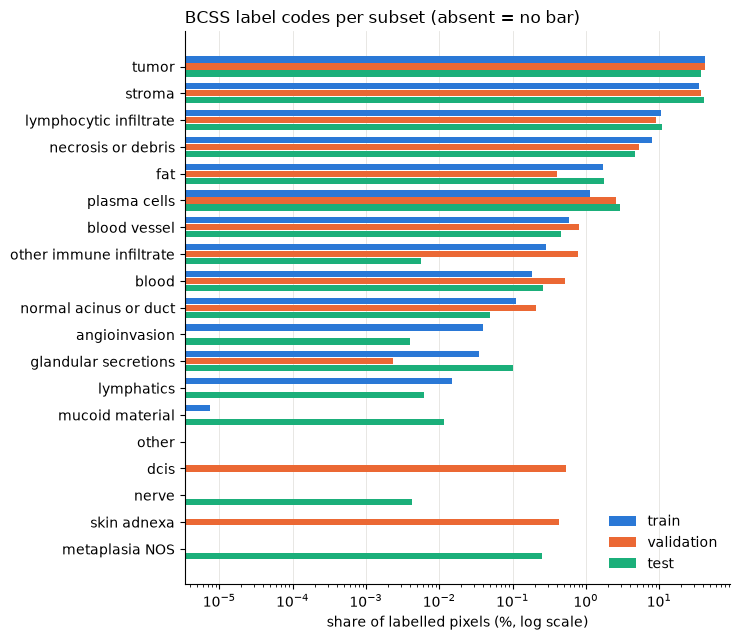

In [5]:
order = share.sort_values("train").index
y = np.arange(len(order))
height = 0.26
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for k, subset in enumerate(["train", "validation", "test"]):
    ax.barh(y + (1 - k) * height, share.loc[order, subset].replace(0, np.nan),
            height=height - 0.03, color=split_colors[subset], label=subset)
ax.set_xscale("log")
ax.set_yticks(y, [name.replace("_", " ") for name in order])
ax.set_xlabel("share of labelled pixels (%, log scale)")
ax.set_title("BCSS label codes per subset (absent = no bar)", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(figure_dir / "class_share_all.png", dpi=200)
plt.show()

### Choosing the annotation granularities

In [6]:
other_codes = [5, 6, 8, 9, 12, 13, 14, 16, 17, 18, 21]
five = {"tumor": tumor_codes, "stroma": [2], "inflammatory": [3, 10, 11], "necrosis": [4], "other": other_codes}

# fine: a code keeps its own class only if it occurs in train, validation and test
kept = [c for c in range(22)
        if c not in ignored_codes and c not in tumor_codes and (present.loc[label_names[c]] > 0).all()]
fine = {"tumor": tumor_codes} | {label_names[c]: [c] for c in kept}
fine["other"] = [c for c in range(22) if c not in ignored_codes + tumor_codes + kept]

all_codes = [c for c in range(22) if c not in ignored_codes]
groupings = {
    "binary": {"non_tumor": [c for c in all_codes if c not in tumor_codes], "tumor": tumor_codes},
    "five": five,
    "fine": fine,
}
for name, grouping in groupings.items():
    assert sorted(c for cs in grouping.values() for c in cs) == all_codes, name
    print(f"{name}: {len(grouping)} classes")

binary: 2 classes
five: 5 classes
fine: 12 classes


In [7]:
def grouped_share(grouping):
    grouped = pd.DataFrame({cls: pixels.loc[[label_names[c] for c in cs]].sum()
                            for cls, cs in grouping.items()}).T
    return grouped.div(grouped.sum()).mul(100).round(2)

grouped_share(groupings["fine"])

subset,train,validation,test
tumor,41.80,42.98,37.71
stroma,35.41,36.82,40.66
lymphocytic_infiltrate,10.69,9.16,11.01
necrosis_or_debris,8.02,5.28,4.74
glandular_secretions,0.04,0.00,0.10
blood,0.18,0.52,0.26
fat,1.73,0.40,1.78
plasma_cells,1.14,2.61,2.95
other_immune_infiltrate,0.28,0.77,0.01
normal_acinus_or_duct,0.11,0.21,0.05


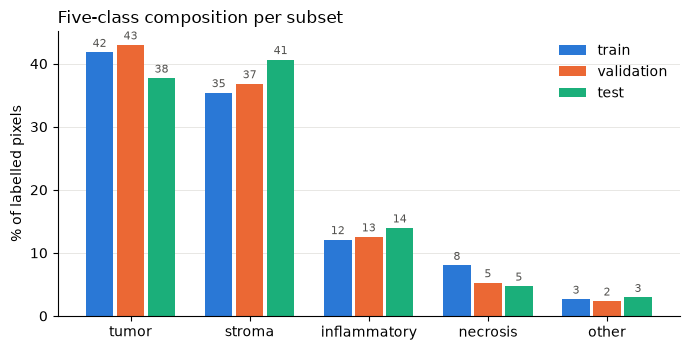

In [8]:
five_share = grouped_share(groupings["five"])
x = np.arange(len(five_share))
width = 0.26
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, subset in enumerate(["train", "validation", "test"]):
    bars = ax.bar(x + (k - 1) * width, five_share[subset], width=width - 0.03,
                  color=split_colors[subset], label=subset)
    ax.bar_label(bars, fmt="%.0f", fontsize=8, color="#52514e", padding=2)
ax.set_xticks(x, five_share.index)
ax.set_ylabel("% of labelled pixels")
ax.set_title("Five-class composition per subset", loc="left")
ax.legend(frameon=False)
ax.grid(axis="y", color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(figure_dir / "class_share_five.png", dpi=200)
plt.show()

### Displaying a few samples

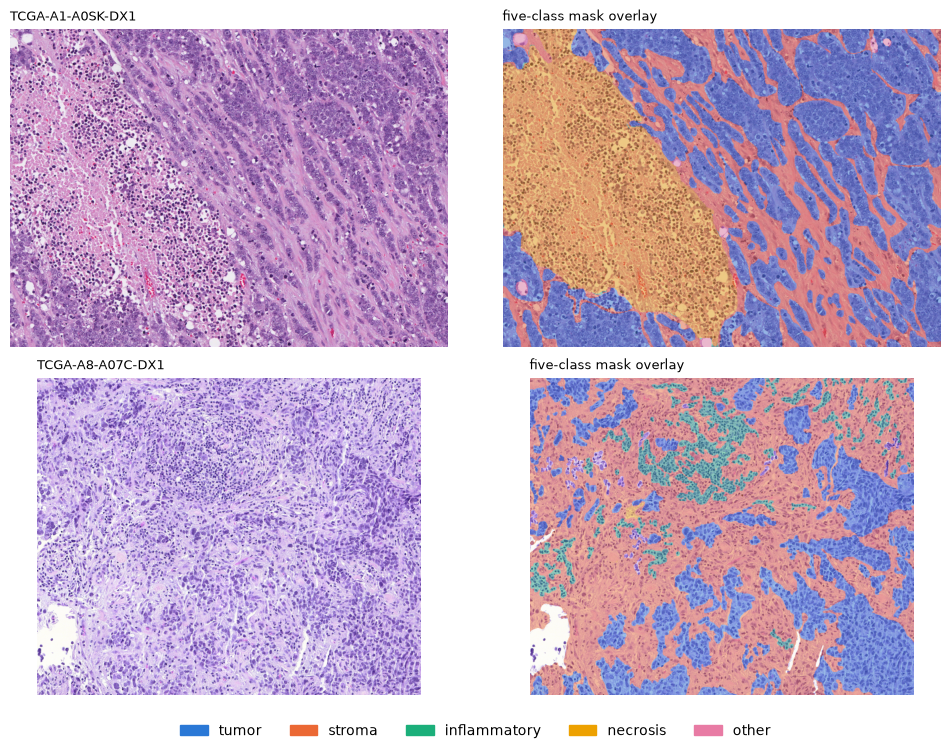

In [9]:
five_colors = np.array([[42, 120, 214], [235, 104, 52], [27, 175, 122], [237, 161, 0], [232, 123, 164]], "uint8")
lookup = np.full(256, 255, "uint8")
for index, cs in enumerate(groupings["five"].values()):
    lookup[cs] = index

def overlay(fname, max_side=900):
    img = Image.open(input_dir / fname).convert("RGB")
    scale = max_side / max(img.size)
    size = (int(img.width * scale), int(img.height * scale))
    img = np.asarray(img.resize(size))
    target = lookup[np.asarray(Image.open(target_dir / fname).resize(size, Image.NEAREST))]
    colored = np.where(target[..., None] < 5, five_colors[np.minimum(target, 4)], img)
    return img, (0.55 * img + 0.45 * colored).astype("uint8")

fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
for row, fname in zip(axes, rois[rois.subset == "train"].fname.iloc[[0, 20]]):
    img, mixed = overlay(fname)
    row[0].imshow(img)
    row[0].set_title(fname.split("_")[0], loc="left", fontsize=9)
    row[1].imshow(mixed)
    row[1].set_title("five-class mask overlay", loc="left", fontsize=9)
    for ax in row:
        ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=c / 255) for c in five_colors]
fig.legend(handles, list(groupings["five"]), loc="lower center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(figure_dir / "example_overlays.png", dpi=150)
plt.show()

### Making the train, validation and test subsets

In [10]:
new_base_dir = pathlib.Path("bcss_split")

def make_subset(subset_name):
    for folder, source_dir in (("images", input_dir), ("masks", target_dir)):
        dir = new_base_dir / subset_name / folder
        os.makedirs(dir, exist_ok=True)
        for fname in rois[rois.subset == subset_name].fname:
            if not (dir / fname).exists():
                shutil.copyfile(src=source_dir / fname, dst=dir / fname)

make_subset("train")
make_subset("validation")
make_subset("test")

with open(new_base_dir / "class_groupings.json", "w") as f:
    json.dump({"ignored_codes": ignored_codes, "groupings": groupings}, f, indent=2)

for subset in ("train", "validation", "test"):
    print(subset, len(list((new_base_dir / subset / "images").glob("*.png"))), "ROIs")

train 83 ROIs
validation 23 ROIs
test 45 ROIs
